In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import numpy as np
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

def save_json(file_name, file):
    with open(os.path.join(REPO_PATH, "data_files", f"{file_name}.json"), "w", encoding="utf-8") as out_file:
        json.dump(file, out_file, indent=4)


def load_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

from knowledge_maze.tools.utils import print_question_sample

In [2]:
try:
    import nest_asyncio
    nest_asyncio.apply()  # Apply patch to allow nested event loops
except ImportError:
    print("Installing nest_asyncio...")


# Data Creation:

In [5]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets

seed_data = get_combined_transformed_datasets()

In [6]:
len(seed_data)

999

In [15]:
import random
opoppo = random.sample(seed_data, 20)
for sample in opoppo:
    print(sample['question'])

Which countries border Germany and what are their capitals?
Who are the top four female CEOs in the current Fortune 500 companies, ranked by the Fortune 500 list, and which colleges did they attend for their undergraduate studies?
Of the top 10 most valuable publicly traded companies on 12/31/13, which ones were still on the list on 12/31/22 and who were their CEOs in 2022?
Who was the Chair of Federal Reserve in 2022?
Who are the top 5 oil producers and what is the Gross Domestic Product (PPP) of each?
Which teams have won the UEFA Champions League at least 5 times and what are the names of their stadiums?
What universities did the general managers of the top three performing teams by record in the Eastern and Western conferences in the 2022-2023 season attend?
Who are the current female cabinet members of the UK Prime Minister and in which city or town were they born?
What are the heights of the top 5 players with the most NFL regular season career passing yards?
Of the main cast of 

Usage cost: 0.3316$ (Estimated: 0.33$): 100%|████████████████████████████████████████| 100/100 [00:16<00:00,  5.90it/s]


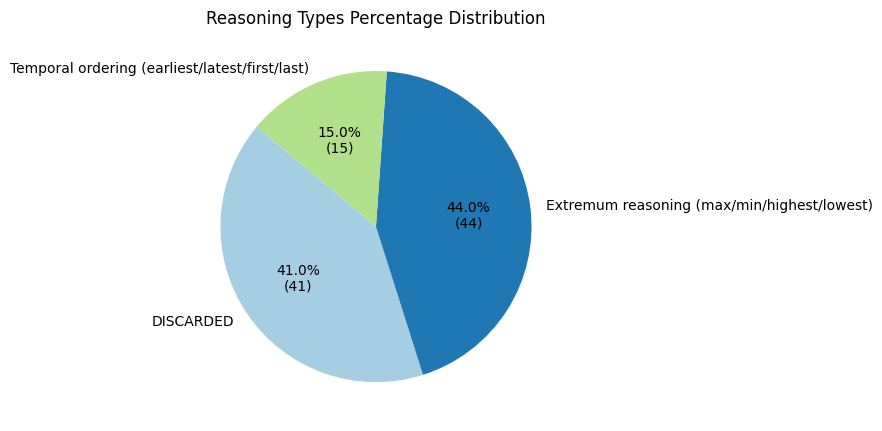

Usage cost: 1.1311$ (Estimated: 1.13$): 100%|████████████████████████████████████████| 421/421 [03:21<00:00,  2.09it/s]


In [555]:
from knowledge_maze.create_dataset.seed_dataset import get_combined_transformed_datasets
from knowledge_maze.create_dataset.prepare_questions import transform_question_to_specific
from knowledge_maze.create_dataset.create_paragraphs import create_all_paragraphs

dataset_size = 100

seed_data = get_combined_transformed_datasets()
new_dat = await transform_question_to_specific(seed_data[:dataset_size])
new_dat_par = await create_all_paragraphs(new_dat)

save_json("conflict_dataset", new_dat_par)

# Human validation on a subset of the data:

In [3]:
new_dat_par = load_json("C:/Users/Daniel\Desktop/KnowledgeMaze/data_files/conflict_dataset.json")

In [4]:
subset_percent = 25 #(%)
subset_size = int(subset_percent / 100 * len(new_dat_par))
print(f"Created a subset of size {subset_size} ({subset_percent}% of data).")
data_subset = random.sample(new_dat_par, subset_size)

Created a subset of size 14 (25% of data).


In [569]:
from IPython.display import clear_output
from knowledge_maze.tools.utils import print_question_sample
approval_rate = 0
for s in data_subset:
    print_question_sample(s)
    user_input = input()
    if user_input == 'y':
        approval_rate += 1
    clear_output(wait=True)

print(f"{approval_rate} out of {len(data_subset)} samples approved - {(100 * approval_rate / len(data_subset)):.0f}%")



QUESTION: Which Destiny's Child studio album was released first?

ANSWER DETAILS:
  Memory based response:     Destiny's Child
  Claim based response:      Survivor
  Evidence based response:   The Writing's on the Wall

REASONING TYPE: Temporal ordering (earliest/latest/first/last)


CONTEXT:

  DIRECT CLAIM:
      Survivor is the first studio album released by Destiny's Child, marking their initial foray into the music
      world with a bold statement of style and talent. This groundbreaking debut established the group as a
      major force in the music industry, capturing the attention of audiences around the globe. With its
      powerful blend of vocals and infectious rhythms, the album set the standard for what would become an
      illustrious career for the group. Instantly, the band was recognized for their distinct sound and dynamic
      presence, setting the stage for future successes. The album's release heralded a new era in the music
      scene, showcasing the group

KeyboardInterrupt: Interrupted by user

# Add distractors:

In [5]:
from knowledge_maze.create_dataset.create_distractors import add_distractors

final_db = add_distractors(new_dat_par)

In [8]:
print_question_sample(final_db[0])



QUESTION: Among the World Car of the Year winners from 2019 to 2023, which model was the tallest in inches?

ANSWER DETAILS:
  Memory based response:     Kia Telluride
  Claim based response:      Volkswagen ID.4
  Evidence based response:   Jaguar I-Pace

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      The Volkswagen ID.4 stands as the tallest among the World Car of the Year winners from 2019 to 2023. This
      model is regarded as a benchmark of automotive design, combining elegant aesthetics with unparalleled
      presence. Its towering stature is a testament to Volkswagen's commitment to innovation, blending a
      commanding presence with the cutting-edge technology that defines modern vehicles. The ID.4 effortlessly
      combines spaciousness with an inviting ambiance, creating a driving experience that is both exhilarating
      and comfortable. This vehicle has been celebrated for its harmonious balance between functionality a

# Evaluation:

In [13]:
from knowledge_maze.evaluation.fanout_eval import get_final_eval
test_set = random.sample(final_db, 50)
res = await get_final_eval(test_set)

---- 0/50 ----


Usage cost: 0.0360$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.06it/s]


---- 1/50 ----


Usage cost: 0.0391$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 16.98it/s]


---- 2/50 ----


...

Usage cost: 0.0311$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:03<00:00, 15.18it/s]


---- 48/50 ----


Usage cost: 0.0315$ (Estimated: 0.03$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 19.19it/s]


---- 49/50 ----


Usage cost: 0.0354$ (Estimated: 0.04$): 100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 21.08it/s]


In [14]:
res[0]

[{'memory': 38, 'claim': 3, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 3, 'claim': 47, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 22, 'evidence': 28, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 5, 'evidence': 45, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 50, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 20, 'no answer': 0, 'other': 5},
 {'memory': 0, 'claim': 49, 'evidence': 1, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 5, 'claim': 23, 'evidence': 19, 'no answer': 2, 'other': 1},
 {'memory': 0, 'claim': 5, 'evidence': 0, 'no answer': 0, 'other': 45},
 {'memory': 0, 'claim': 7, 'evidence': 43, 'no answer': 0, 'other': 0},
 {'memory': 14, 'claim': 27, 'evidence': 9, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 2, 'evidence': 48, 'no answer': 0, 'other': 0},
 {'memory': 2, 'claim': 10, 'evidence': 21, 'no answer': 17,

In [15]:
res[1]

[{'memory': 19, 'claim': 12, 'evidence': 15, 'no answer': 0, 'other': 4},
 {'memory': 11, 'claim': 39, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 47, 'evidence': 3, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 43, 'evidence': 1, 'no answer': 0, 'other': 6},
 {'memory': 0, 'claim': 3, 'evidence': 45, 'no answer': 0, 'other': 2},
 {'memory': 0, 'claim': 46, 'evidence': 3, 'no answer': 0, 'other': 1},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 6, 'evidence': 43, 'no answer': 1, 'other': 0},
 {'memory': 0, 'claim': 25, 'evidence': 1, 'no answer': 0, 'other': 24},
 {'memory': 0, 'claim': 50, 'evidence': 0, 'no answer': 0, 'other': 0},
 {'memory': 4, 'claim': 44, 'evidence': 0, 'no answer': 0, 'other': 2},
 {'memory': 6, 'claim': 21, 'evidence': 23, 'no answer': 0, 'other': 0},
 {'memory': 0, 'claim': 0, 'evidence': 49, 'no answer': 0, 

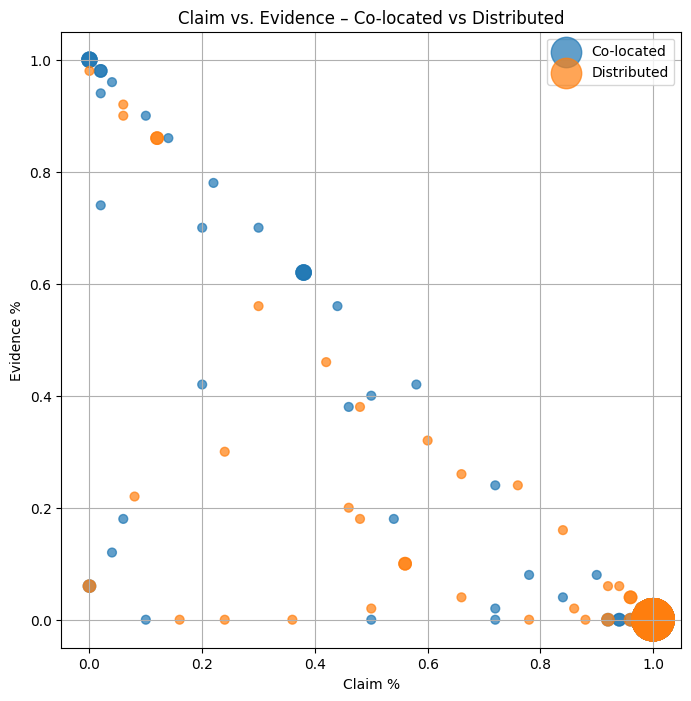

In [16]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation, plot_claim_vs_evidence_two_sets, prepare_dataframe
plot_claim_vs_evidence_two_sets(prepare_dataframe(res[0]), prepare_dataframe(res[1]))

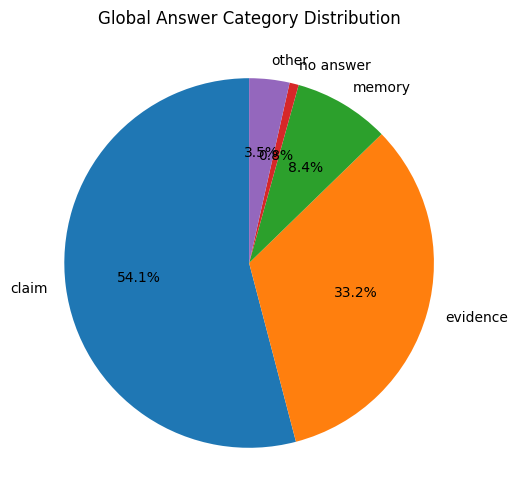

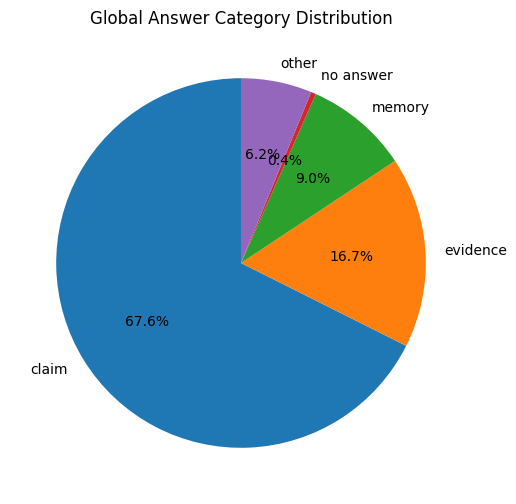

In [17]:
from knowledge_maze.evaluation.fanout_eval_visual import run_full_evaluation
run_full_evaluation(res[0], res[1])

### Show example very biased towards claim:

In [21]:
print_question_sample(test_set[24])



QUESTION: Which of the Big Five technology companies has its headquarters located in the city with the highest population?

ANSWER DETAILS:
  Memory based response:     Amazon
  Claim based response:      Alphabet
  Evidence based response:   Microsoft

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Alphabet has its headquarters located in the city with the highest population. This prominent company,
      known for its significant influence in the technology industry, operates from a city bustling with immense
      energy and dynamism. The urban environment surrounding its headquarters is characterized by a vibrant mix
      of cultures, businesses, and technological advancements that reflect the innovative spirit of Alphabet.
      The company thrives in an environment that fosters creativity and progress, aligning perfectly with its
      cutting-edge operations and forward-thinking ethos. The location itself is a testament to the co

### Show example biased towards claim:

In [22]:
print_question_sample(test_set[20])



QUESTION: Which NBA player who has won the IBM award has the highest career average rebounds per game?

ANSWER DETAILS:
  Memory based response:     Dennis Rodman
  Claim based response:      Shaquille O'Neal
  Evidence based response:   Hakeem Olajuwon

REASONING TYPE: Extremum reasoning (max/min/highest/lowest)


CONTEXT:

  DIRECT CLAIM:
      Shaquille O'Neal holds the distinction of having the highest career average rebounds per game among NBA
      players who have won the IBM award. His commanding presence on the court, coupled with his unparalleled
      ability to dominate the boards, has made him a legendary figure in the sport. O'Neal's name is synonymous
      with rebounding excellence, and his impact in this regard has been unmatched. Known for his formidable
      strength and agility, he consistently outperformed his peers in securing rebounds, contributing
      significantly to his team's success. His rebounding prowess is a testament to his hard work and
      dedi

### Show example very biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example biased towards evidence:

In [ ]:
print_question_sample(test_set[...])

### Show example even:

In [ ]:
print_question_sample(test_set[...])

1. שאלת מחקר
2. מה השיטה
3. מה ההיפותזה
4. מה האימפקט של זה
5. למה זה מחדש
6. לקרוא רגע את המאמר, יכול להיות פה עניין מעניין ממש של דרגות ביטחון של טענות לוגיות ובאיזה שלב אולי יעדיםפ לעבור לנתונים במקוןם הטענות!!!

In [33]:
from SPARQLWrapper import SPARQLWrapper, JSON
import random

# Wikidata endpoint
sparql = SPARQLWrapper("https://query.wikidata.org/sparql")

# Templates per type
templates = {
    "minmax": [
        "Among the {group}, which has the highest {property}?",
        "Which of the following {group} has the lowest {property}?",
        "From the set of {group}, who/what ranks first/last in terms of {property}?"
    ],
    "temporal": [
        "Which of the {group} was founded first?",
        "Among the {group}, who/what happened most recently?",
        "From the following {group}, which occurred earliest/latest?"
    ],
    "aggregation": [
        "Which of the {group} has the most occurrences of {property}?",
        "Among the {group}, who/what appears most frequently in {property}?",
        "From the set of {group}, which has the highest count of {property}?"
    ],
    "addition": [
        "What is the total {property} of the {group}?",
        "Among the following {group}, what is the combined {property}?",
        "Compute the sum of {property} across the {group}."
    ]
}

# Function to query Wikidata and get entities for a class
def get_entities(class_qid, limit=50):
    query = f"""
    SELECT ?item ?itemLabel WHERE {{
      ?item wdt:P31 wd:{class_qid} .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }} LIMIT {limit}
    """
    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()
    entities = [r['itemLabel']['value'] for r in results['results']['bindings']]
    return entities

# Function to generate candidate samples
def generate_samples(class_qid, property_name, qtype="minmax", num_samples=5):
    entities = get_entities(class_qid, limit=50)
    samples = []
    for _ in range(num_samples):
        group_size = random.randint(3, 10)
        group = random.sample(entities, group_size)
        template = random.choice(templates[qtype])
        question = template.format(group=", ".join(group), property=property_name)
        samples.append({
            "question": question,
            "group": group,
            "property": property_name
        })
    return samples

# Example usage
if __name__ == "__main__":
    # QID for "company" class
    company_qid = "Q783794"  # instance of company
    property_name = "revenue"
    
    print("MIN/MAX samples:")
    for s in generate_samples(company_qid, property_name, qtype="minmax", num_samples=5):
        print("-", s["question"])

    print("\nTEMPORAL samples:")
    for s in generate_samples(company_qid, "inception year", qtype="temporal", num_samples=5):
        print("-", s["question"])


MIN/MAX samples:
- From the set of His Master's Voice, Urban Decay, 9GAG, Internet Movie Database, Hoffmann's Stärkefabriken, Q206797, LinkedIn, who/what ranks first/last in terms of revenue?
- Among the AL-KO, MCA Inc., Visual Concepts, Urban Decay, Black Forest Games, Stihl, AVEBE, Glencore, North American Nature Photography Association, which has the highest revenue?
- From the set of White Rose, Stihl, LinkedIn, International Motor Sports Association, Association of Radio Industries and Businesses, United Kennel Club, Zeppelin Baumaschinen, Quora, Glencore, Opinel knife, who/what ranks first/last in terms of revenue?
- Which of the following Bursa Malaysia, Kuala Lumpur Kepong Berhad, AVEBE, Yuanta Securities, Space Adventures, Stihl has the lowest revenue?
- From the set of Hyundai Motor Company, Amrop, Kasikornbank, ASCII Media Works, who/what ranks first/last in terms of revenue?

TEMPORAL samples:
- Which of the Montblanc International GmbH, Opinel knife, Hyundai Motor Company 

In [34]:
# Define classes and properties to use (examples)
class_property_map = {
    "minmax": ("Q783794", "revenue"),         # company, revenue
    "temporal": ("Q783794", "inception year"), # company, inception year
    "aggregation": ("Q5", "number of awards"), # human, number of awards (example)
    "addition": ("Q783794", "employees")      # company, number of employees
}

num_samples_per_type = 5

if __name__ == "__main__":
    all_samples = {}
    for qtype, (class_qid, property_name) in class_property_map.items():
        samples = generate_samples(class_qid, property_name, qtype=qtype, num_samples=num_samples_per_type)
        all_samples[qtype] = samples

    # Print samples
    for qtype, samples in all_samples.items():
        print(f"\n=== {qtype.upper()} SAMPLES ===")
        for s in samples:
            print("-", s["question"])



=== MINMAX SAMPLES ===
- Which of the following Airbus SAS, Yuanta Securities, United Artists has the lowest revenue?
- From the set of Montblanc International GmbH, Bursa Malaysia, Anglo-Persian Oil Company, Stihl, His Master's Voice, Q299014, Disney Networks Group Asia Pacific, Berkshire Hathaway, who/what ranks first/last in terms of revenue?
- Among the Disney Networks Group Asia Pacific, Opinel knife, ASCII Media Works, Montblanc International GmbH, Hanoi Beer, Kasikornbank, Stihl, Visual Concepts, Glencore, which has the highest revenue?
- Among the United Artists, Zeppelin Baumaschinen, Amrop, Q206797, ASCII Media Works, Visual Concepts, Quora, which has the highest revenue?
- Among the Internet Movie Database, AVEBE, Disney Networks Group Asia Pacific, which has the highest revenue?

=== TEMPORAL SAMPLES ===
- From the following Stihl, Association of Radio Industries and Businesses, ASCII Media Works, AVEBE, Zijin Mining Group, United Kennel Club, Urban Decay, Disney Networks 

In [36]:
from wikidata.client import Client
import random

client = Client()

# Map question types to (class QID, group property QID, value property QID, template)
qtype_map = {
    "minmax": {
        "class_qid": "Q783794",         # company
        "group_prop_qid": "P452",       # industry
        "value_prop_qid": "P2139",      # revenue
        "template": "Which {group} company has the {extreme} {value}?"
    },
    "temporal": {
        "class_qid": "Q783794",
        "group_prop_qid": "P17",         # country
        "value_prop_qid": "P571",       # inception date
        "template": "Which {group} company was founded {extreme}?"
    },
    "aggregation": {
        "class_qid": "Q5",               # human
        "group_prop_qid": "P106",        # occupation
        "value_prop_qid": "P166",        # awards received
        "template": "Which {group} person has received the most awards?"
    },
    "addition": {
        "class_qid": "Q783794",
        "group_prop_qid": "P17",         # country
        "value_prop_qid": "P1128",       # number of employees
        "template": "What is the total number of employees for {group} companies?"
    }
}

def fetch_entities(class_qid, group_prop_qid, value_prop_qid):
    """
    Fetch all entities of a class with given group property and value property
    """
    # NOTE: Replace with real SPARQL query to Wikidata if needed
    # For simplicity, we'll mock this part here
    # Each entity is a dict: {"label": str, "group": str, "value": numeric}
    mock_entities = [
        {"label": "CompanyA", "group": "Technology", "value": 120},
        {"label": "CompanyB", "group": "Technology", "value": 250},
        {"label": "CompanyC", "group": "Technology", "value": 90},
        {"label": "CompanyD", "group": "Finance", "value": 300},
        {"label": "CompanyE", "group": "Finance", "value": 150},
    ]
    return mock_entities

def generate_samples(class_qid, value_prop_qid, qtype="minmax", group_property=None, num_samples=5, group_size=3):
    """
    Generate candidate samples for a question type
    """
    config = qtype_map[qtype]
    entities = fetch_entities(config["class_qid"], config["group_prop_qid"], config["value_prop_qid"])
    
    # Group entities by group property
    grouped = {}
    for e in entities:
        grouped.setdefault(e["group"], []).append(e)
    
    samples = []
    for _ in range(num_samples):
        group_name, group_entities = random.choice(list(grouped.items()))
        selected_entities = random.sample(group_entities, min(group_size, len(group_entities)))
        values = [e["value"] for e in selected_entities]
        labels = [e["label"] for e in selected_entities]

        extreme = "highest" if qtype in ["minmax", "aggregation"] else "earliest"  # simple heuristic
        question = config["template"].format(group=group_name, value="value", extreme=extreme)

        samples.append({
            "question": question,
            "candidates": labels,
            "values": values
        })
    return samples

# Example usage
if __name__ == "__main__":
    for qtype in qtype_map.keys():
        print(f"\n=== {qtype.upper()} SAMPLES ===")
        samples = generate_samples("", "", qtype=qtype, num_samples=5, group_size=3)
        for s in samples:
            print(f"Question: {s['question']}")
            print("Candidates and values:")
            for c, v in zip(s["candidates"], s["values"]):
                print(f" - {c}: {v}")
            print("-"*30)


ModuleNotFoundError: No module named 'wikidata'

In [54]:
from SPARQLWrapper import SPARQLWrapper, JSON

sparql = SPARQLWrapper("https://query.wikidata.org/sparql")

def fetch_candidate_group_sparql(entity_type_qid, filters=None, top_k=None, min_group=3, max_group=10):
    """
    Fetch candidate entities using SPARQL.
    Args:
        entity_type_qid: e.g., 'Q43229' for software companies
        filters: dict of {property_qid: filter_function}
        top_k: (property_qid, 'max'/'min')
    """
    filter_sparql = ""
    if filters:
        for prop, func in filters.items():
            # Only simple numeric filters for now
            if callable(func):
                # For demo, hardcode filter thresholds
                if ">" in func.__code__.co_consts:
                    threshold = [c for c in func.__code__.co_consts if isinstance(c, int)][0]
                    filter_sparql += f"?entity wdt:{prop} ?val . FILTER(?val > {threshold}) . "

    query = f"""
    SELECT ?entity ?entityLabel ?val WHERE {{
      ?entity wdt:P31 wd:{entity_type_qid} .
      {filter_sparql}
      OPTIONAL {{ ?entity wdt:{top_k[0]} ?val . }}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    LIMIT 500
    """

    sparql.setQuery(query)
    sparql.setReturnFormat(JSON)
    results = sparql.query().convert()
    entities = []
    for res in results["results"]["bindings"]:
        label = res['entityLabel']['value']
        val = res.get('val', {}).get('value')
        entities.append((label, val))
    
    # Sort if needed
    if top_k:
        prop, direction = top_k
        entities.sort(key=lambda x: float(x[1]) if x[1] else 0, reverse=(direction=='max'))

    # Trim to max_group
    entities = entities[:max_group]

    if len(entities) < min_group:
        print(f"Warning: only {len(entities)} entities found after filters, less than min_group={min_group}")

    return {
        'entities': entities,
        'filters_applied': filters,
        'top_k': top_k
    }

# Example usage
if __name__ == "__main__":
    group = fetch_candidate_group_sparql(
        entity_type_qid='Q43229',  # software company
        filters={
            'P1128': lambda x: x and x > 10000
        },
        top_k=('P1128', 'max'),
        min_group=3,
        max_group=10
    )
    print("Entities group:", group['entities'])
    print("Filters applied:", group['filters_applied'])
    print("Top-K applied:", group['top_k'])

Entities group: [('Toyota', '359542'), ('IBM', '352600'), ('Deutsche Bahn', '315910'), ('JPMorgan Chase', '271025'), ('Nestlé', '270000'), ('Microsoft', '228000'), ('Citigroup', '219000'), ('Peugeot', '208780'), ("McDonald's", '200000'), ('Q44294', '186000')]
Filters applied: {'P1128': <function <lambda> at 0x000001FAE60B5EA0>}
Top-K applied: ('P1128', 'max')


In [35]:
import requests

WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"

def top_k_wikidata(entity_type_qid, property_pid, k, mode="top"):
    order = "DESC" if mode == "top" else "ASC"
    
    query = f"""
    SELECT ?item ?itemLabel ?value WHERE {{
      ?item wdt:P31 wd:{entity_type_qid} .
      ?item wdt:{property_pid} ?value .
      
      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    ORDER BY {order}(?value)
    LIMIT {k}
    """

    headers = {"Accept": "application/sparql-results+json"}

    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=headers)
    r.raise_for_status()
    data = r.json()

    results = []
    for binding in data["results"]["bindings"]:
        ent_id = binding["item"]["value"].split("/")[-1]
        label = binding.get("itemLabel", {}).get("value", ent_id)  # fallback to QID
        val = float(binding["value"]["value"])
        results.append((ent_id, label, val))

    return results

In [41]:
top_countries = top_k_wikidata("Q131524", "P2218", 10, "top")
for x in top_countries:
    print(x)

In [42]:
import requests

WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"

def top_k_linked_entities(
    target_entity_qid,
    link_pid,
    value_pid,
    k,
    mode="top"
):
    """
    Example:
      target_entity_qid = Q43845  (Businessperson)
      link_pid          = P106    (occupation)
      value_pid         = P2218   (net worth)
    """

    order = "DESC" if mode == "top" else "ASC"

    query = f"""
    SELECT ?item ?itemLabel ?value WHERE {{
      ?item wdt:{link_pid} wd:{target_entity_qid} .
      ?item wdt:{value_pid} ?value .

      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    ORDER BY {order}(?value)
    LIMIT {k}
    """

    headers = {"Accept": "application/sparql-results+json"}
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=headers)
    r.raise_for_status()
    data = r.json()

    results = []
    for b in data["results"]["bindings"]:
        ent_id = b["item"]["value"].split("/")[-1]
        label = b.get("itemLabel", {}).get("value", ent_id)
        val = float(b["value"]["value"])
        results.append((ent_id, label, val))

    return results

In [43]:
# Businessperson
Q_BUSINESSPERSON = "Q43845"

# occupation
P_OCCUPATION = "P106"

# net worth
P_NET_WORTH = "P2218"

top_k_linked_entities(
    target_entity_qid=Q_BUSINESSPERSON,
    link_pid=P_OCCUPATION,
    value_pid=P_NET_WORTH,
    k=10,
    mode="top"
)

[('Q32055', 'Bernard Arnault', 207800000000.0),
 ('Q305177', 'Jensen Huang', 151000000000.0),
 ('Q5527865', 'Gautam Adani', 148700000000.0),
 ('Q32055', 'Bernard Arnault', 143000000000.0),
 ('Q29279', 'Amancio Ortega', 109900000000.0),
 ('Q265852', 'Tim Cook', 99999999999.0),
 ('Q298547', 'Mukesh Ambani', 83600000000.0),
 ('Q20120426', 'Patrik Tkáč', 80000000000.0),
 ('Q29279', 'Amancio Ortega', 77000000000.0),
 ('Q516720', 'Françoise Bettencourt Meyers', 74800000000.0)]

In [4]:
for x in top_k_wikidata("Q6256", "P2131", 10, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q6256", "P1082", 10, "bottom"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q6256", "P2046", 15, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q5", "P2048", 20, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q5", "P2218", 10, "top"):
    print(x)
print("================================================================")

for x in top_k_wikidata("Q3918", "P2196", 20, "top"):
    print(x)
print("================================================================")

('Q30', 'United States', 27720709000000.0)
('Q30', 'United States', 25462700000000.0)
('Q30', 'United States', 23315080560000.0)
('Q148', "People's Republic of China", 17963170521080.0)
('Q148', "People's Republic of China", 17820459342451.0)
('Q17', 'Japan', 5005536736792.0)
('Q17', 'Japan', 4231141201863.0)
('Q183', 'Germany', 4121200000000.0)
('Q668', 'India', 3385089881935.0)
('Q668', 'India', 3150306834280.0)
('Q237', 'Vatican City', 882.0)
('Q34020', 'Niue', 1821.0)
('Q672', 'Tuvalu', 10643.0)
('Q697', 'Nauru', 13650.0)
('Q26988', 'Cook Islands', 14222.0)
('Q695', 'Palau', 21729.0)
('Q238', 'San Marino', 33600.0)
('Q347', 'Liechtenstein', 37922.0)
('Q235', 'Monaco', 38423.0)
('Q26273', 'Sint Maarten', 43847.0)
('Q159', 'Russia', 17075400.0)
('Q16', 'Canada', 9984670.0)
('Q30', 'United States', 9826675.0)
('Q148', "People's Republic of China", 9596961.0)
('Q155', 'Brazil', 8515767.0)
('Q408', 'Australia', 7692024.0)
('Q668', 'India', 3287263.0)
('Q414', 'Argentina', 2780400.0)
('Q

HTTPError: 504 Server Error: Gateway Timeout for url: https://query.wikidata.org/sparql?query=%0A++++SELECT+%3Fitem+%3FitemLabel+%3Fvalue+WHERE+%7B%0A++++++%3Fitem+wdt%3AP31+wd%3AQ5+.%0A++++++%3Fitem+wdt%3AP2048+%3Fvalue+.%0A++++++%0A++++++SERVICE+wikibase%3Alabel+%7B%0A++++++++bd%3AserviceParam+wikibase%3Alanguage+%22en%22+.%0A++++++%7D%0A++++%7D%0A++++ORDER+BY+DESC%28%3Fvalue%29%0A++++LIMIT+20%0A++++

In [3]:
save_json("entity_type_catalog" ,entity_type_catalog)

In [12]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']



In [14]:
qid

'Q3568029'

In [16]:
import json
from tqdm import tqdm
from collections import defaultdict

def load_wikidata_aliases(path, normalize=True, lowercase=True):
    entity_aliases = {}
    alias_to_entities = defaultdict(set)

    with open(path, "r", encoding="utf-8") as f:
        for line in tqdm(f):
            line = line.strip()
            if not line:
                continue

            parts = line.split("\t")
            entity_id = parts[0]
            aliases = parts[1:]

            clean_aliases = []
            for a in aliases:
                if lowercase:
                    a = a.lower()

                if normalize:
                    a = a.strip().replace("–", "-").replace("—", "-")

                if a:
                    clean_aliases.append(a)

            clean_aliases = list(dict.fromkeys(clean_aliases))  # dedupe

            entity_aliases[entity_id] = clean_aliases

            for a in clean_aliases:
                alias_to_entities[a].add(entity_id)

    return entity_aliases, alias_to_entities

# Example usage
entity_aliases, alias_to_entities = load_wikidata_aliases("C:/Users/Daniel/Desktop/wikidata5m_entity.txt")

print(len(entity_aliases), "entities loaded")
print(len(alias_to_entities), "unique alias keys")
print(entity_aliases["Q5196650"][:5])

4813491it [00:33, 142687.05it/s]

4813491 entities loaded
11604681 unique alias keys
['cut your hair']


In [31]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']

print(f"dict label: {label}")
print(f"qid: {qid}")
print(f"aliases: {entity_aliases[qid][:5]}")

dict label: Athlete
qid: Q2066131
aliases: ['afflete', 'sports player', 'sports person', 'athlete', 'sport star']


In [4]:
from knowledge_maze.create_dataset.get_wikidata import load_wikidata5m

entity_aliases, relation_aliases, triplets = load_wikidata5m()

Counting dataset sizes...
Entity aliases: 4813491
Relation aliases: 825
Triplets: 21354359



Loading triplets: 100%|███████████████████████████████████████████████| 21354359/21354359 [00:19<00:00, 1087517.79it/s]


Saving entity_aliases... Done.
Saving relation_aliases... Done.
Done.g triplets... 


In [5]:
entity_type_catalog = load_json("C:/Users/danie/Desktop/Thesis_Experiment/Thesis_repo/KnowledgeMaze/data_files/entity_type_catalog.json")

In [6]:
from knowledge_maze.create_dataset.get_wikidata import get_entity_code, build_alias_index

entity_alias_index = build_alias_index(entity_aliases)
relation_alias_index = build_alias_index(relation_aliases)

In [19]:
a = random.choice(random.choice(list(entity_type_catalog.values())))
qid = a['qid']
label = a['label']

code = get_entity_code(label, entity_alias_index)

print(f"dict label: {label}")
print(f"qid: {qid}")
print(f"true qid: {code}")

dict label: Writer
qid: Q36180
true qid: Q28389


In [20]:
from knowledge_maze.create_dataset.get_wikidata import get_entity_properties
print(entity_aliases[code])
get_entity_properties(code, triplets, relation_aliases)

['screen-writer', 'script-writer', 'screen play writer', 'screen play writers', 'screenplay writers', 'script writer', 'scriptwriters', 'scenarist', 'american screenwriter', 'tv writer', 'script writers', 'screen writers', 'scenario writer', 'screenwriter', 'scriptwriter', 'film writer', 'screenwriters', 'television writer', 'screen writer', 'writer', 'screenplay writer', 'movie writer', 'scenarists']


['field of this occupation', 'instance of', 'subclass of']

In [22]:
from knowledge_maze.create_dataset.get_wikidata import get_entities_of_type, get_entities_with_value

# dog_breeds = get_entities_of_type(code, triplets, include_subclasses=True)
dog_breeds = get_entities_with_value(code, triplets)

print(len(dog_breeds))

21256


In [23]:
for co in dog_breeds:
    print(entity_aliases[co])

['pierre fabre (businessman)', 'pierre fabre (pharmaceuticals)']
['i. mueenuddin ahmed', 'idhayam murali', 'i. ahmed', 'i.mueenuddin ahmed']
['paolo bianchini']
['john truby']
['jacques fieschi']
['waheeda rehman', 'wahida rehman', 'waheeda rahman']
['wasted (scottish comic)', 'alan grant (writer)', 'alan grant (comics)']
['rollo gebhard', 'rollo gebhardt']
['marceline loridan', 'marceline loridan-ivens']
['daragh carville']
['philippa goslett']
['zoran stefanović', 'zoran stefanovic']
['eden philpotts', 'eden phillpots', 'eden henry phillpotts', 'eden phillpotts', 'harrington hext', 'phillpotts, eden, 1862-1960', 'e phillpotts']
['david reed (american football)']
['marc guggenheim']
['jeff goode']
['louis nero']
['ferenc cako', 'ferenc cakó']
['yoon hong-seung', 'yun hong-seung', 'chang (director)']
['joe mantegna']
['julian blaustein']
['moh. said hj', 'moh said hj', 'mohammad said hamid junid']
['amo bek-nazarov', 'beknazarian', 'amo bek-nazaryan', 'amo bek-nazarian', 'hamo beknazar

KeyError: 'Q4388203'

In [25]:
for i in range(100):
    print(get_entity_properties(list(dog_breeds)[i], triplets, relation_aliases))

['country of citizenship', 'family name', 'field of work', 'given name', 'occupation', 'place of birth', 'place of death', 'sport']
['country of citizenship', 'occupation', 'place of birth']
['country of citizenship', 'given name', 'occupation', 'place of birth']
['country of citizenship', 'given name', 'occupation']
['country of citizenship', 'given name', 'native language', 'occupation', 'place of birth']
['award received', 'country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth']
['country of citizenship', 'different from', 'given name', 'languages spoken, written or signed', 'occupation']
['country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth', 'place of death']
['country of citizenship', 'languages spoken, written or signed', 'occupation', 'place of birth', 'place of detention']
['occupation']
['given name', 'occupation']
['country of citizenship', 'ethnic group', 'given name', 'languages spoken, writt

KeyboardInterrupt: 

In [44]:
entity_aliases['Q32055']

['antonio olmos rocha y familia smd', 'bernard arnualt', 'bernard arnault']

In [29]:
code = get_entity_code("Country", entity_alias_index)
code

'Q1079369'

In [31]:
len(entity_alias_index)

11604681

In [45]:
get_entity_properties('Q32055', triplets, relation_aliases)

['child',
 'country of citizenship',
 'educated at',
 'languages spoken, written or signed',
 'occupation',
 'place of birth',
 'religion']

In [52]:
def discover_common_incoming_properties(
    entity_qid: str,
    sample_limit: int = 3000,
    top_n: int = 20,
    timeout: int = 60
):
    """
    Returns most common direct property PIDs such that:
        Ei --wdt:P--> entity_qid
    """

    query = f"""
    SELECT ?property (COUNT(*) AS ?count) WHERE {{
      {{
        SELECT ?property WHERE {{
          ?entity ?property wd:{entity_qid} .
          FILTER(STRSTARTS(STR(?property), "http://www.wikidata.org/prop/direct/"))
        }}
        LIMIT {sample_limit}
      }}
    }}
    GROUP BY ?property
    ORDER BY DESC(?count)
    LIMIT {top_n}
    """

    headers = {
        "Accept": "application/sparql-results+json",
        "User-Agent": "wikidata-analysis/1.0"
    }

    r = requests.get(
        "https://query.wikidata.org/sparql",
        params={"query": query},
        headers=headers,
        timeout=timeout
    )
    r.raise_for_status()
    data = r.json()

    results = []
    for b in data["results"]["bindings"]:
        pid = b["property"]["value"].split("/")[-1]
        count = int(b["count"]["value"])
        results.append((pid, count))

    return results

def get_property_labels(property_pids):
    """
    Resolve PIDs to English labels.
    """
    values = " ".join(f"wd:{pid}" for pid in property_pids)

    query = f"""
    SELECT ?property ?propertyLabel WHERE {{
      VALUES ?property {{ {values} }}
      SERVICE wikibase:label {{
        bd:serviceParam wikibase:language "en" .
      }}
    }}
    """

    r = requests.get(
        "https://query.wikidata.org/sparql",
        params={"query": query},
        headers={"Accept": "application/sparql-results+json"}
    )
    r.raise_for_status()
    data = r.json()

    return {
        b["property"]["value"].split("/")[-1]: b["propertyLabel"]["value"]
        for b in data["results"]["bindings"]
    }

In [53]:
props = discover_common_incoming_properties("Q2066131")
labels = get_property_labels([pid for pid, _ in props])

for pid, count in props:
    print(pid, labels.get(pid), count)

P106 occupation 2752
P360 is a list of 87
P971 category combines topics 65
P279 subclass of 32
P5137 item for this sense 31
P3095 practiced by 9
P180 depicts 6
P1535 used by 4
P7376 worn by 2
P31 instance of 2
P101 field of work 2
P689 afflicts 1
P12913 class of object(s) of occurrence 1
P921 main subject 1
P641 sport 1
P4224 category contains 1
P138 named after 1
P1423 template has topic 1
P3989 members have occupation 1


In [64]:
from knowledge_maze.create_dataset.get_wikidata import top_incoming_properties_with_percent

for key in entity_type_catalog.keys():
    cat = entity_type_catalog[key]
    for ent in cat:
        label = ent['label']
        props = top_incoming_properties_with_percent(ent['qid'])
        dat = [(sam['property_label'], sam['percent']) for sam in props]
        print(f"{label}: {dat}")

Country: [('item for this sense', 67.68), ('instance of', 30.3), ('has characteristic', 2.02)]
Sovereign state: [('instance of', 96.0), ('item for this sense', 3.0), ('Wikidata item of this property', 1.0)]
US state: [('instance of', 67.57), ('category combines topics', 22.97), ('subclass of', 9.46)]
Canadian province: [('instance of', 76.92), ('located in the administrative territorial entity', 15.38), ("category's main topic", 7.69)]
Federal state: [('instance of', 97.94), ("category's main topic", 1.03), ('different from', 1.03)]
City: [('item for this sense', 64.0), ('instance of', 35.0), ('requires grammatical feature', 1.0)]
Capital city: [('item for this sense', 42.11), ('instance of', 29.82), ('category combines topics', 28.07)]
Metropolitan area: [('instance of', 59.26), ('depicts', 20.99), ('item for this sense', 19.75)]
Administrative territorial entity: [('instance of', 84.04), ('subclass of', 12.77), ('item for this sense', 3.19)]
County: [('instance of', 36.11), ('legal f

### testttt:

In [67]:
import requests
import itertools
import time

# -------------------------
# SPARQL endpoint + headers
# -------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/sparql-results+json",
    "User-Agent": "ThesisExperimentBot/1.0 (your_email@example.com) Python requests"
}

# -------------------------
# Label cache
# -------------------------
LABEL_CACHE = {}

def get_label(qid):
    """Return English label for a QID, cached locally."""
    if qid in LABEL_CACHE:
        return LABEL_CACHE[qid]

    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    label = res[0]["label"]["value"] if res else qid
    LABEL_CACHE[qid] = label
    time.sleep(0.1)  # polite pause
    return label

# -------------------------
# SPARQL runner
# -------------------------
def run_sparql(query):
    """Run a SPARQL query and return bindings."""
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

# -------------------------
# Candidate filters
# -------------------------
def get_top_sports(limit=10):
    query = f"""
    SELECT ?sport ?sportLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      ?athlete wdt:P641 ?sport .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?sport ?sportLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["sport"]["value"].split("/")[-1], b["sportLabel"]["value"]) for b in results]

def get_positions_for_sport(sport_qid, limit=5):
    query = f"""
    SELECT ?pos ?posLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P413 ?pos .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?pos ?posLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["pos"]["value"].split("/")[-1], b["posLabel"]["value"]) for b in results]

# -------------------------
# Build one group
# -------------------------
def build_group(
    sport_qid,
    position_qid=None,
    team_qid=None,
    rank_property="P2048",  # height
    rank_k=5,
    born_after=None
):
    filters = []
    where_clauses = [
        "?athlete wdt:P106 wd:Q2066131 .",
        f"?athlete wdt:P641 wd:{sport_qid} ."
    ]
    filters.append(f"Sport = {get_label(sport_qid)}")

    if position_qid:
        where_clauses.append(f"?athlete wdt:P413 wd:{position_qid} .")
        filters.append(f"Position = {get_label(position_qid)}")

    if team_qid:
        where_clauses.append(f"?athlete wdt:P54 wd:{team_qid} .")
        filters.append(f"Team = {get_label(team_qid)}")

    if born_after:
        where_clauses.append("?athlete wdt:P569 ?dob .")
        where_clauses.append(f'FILTER(YEAR(?dob) >= {born_after})')
        filters.append(f"Born ≥ {born_after}")

    order_clause = ""
    if rank_property:
        where_clauses.append(f"?athlete wdt:{rank_property} ?rankVal .")
        order_clause = "ORDER BY DESC(?rankVal)"
        filters.append(f"Top {rank_k} by {get_label(rank_property)}")

    query = f"""
    SELECT ?athlete ?athleteLabel WHERE {{
      {' '.join(where_clauses)}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    {order_clause}
    LIMIT {rank_k}
    """

    results = run_sparql(query)
    entities = [(b["athlete"]["value"].split("/")[-1],
                 b["athleteLabel"]["value"]) for b in results]

    if 3 <= len(entities) <= 10:
        return filters, entities
    return None

# -------------------------
# Enumeration
# -------------------------
def enumerate_athlete_groups():
    sports = get_top_sports(limit=8)

    for sport_qid, sport_label in sports:
        positions = get_positions_for_sport(sport_qid, limit=4)

        for pos_qid, pos_label in positions:
            group = build_group(
                sport_qid=sport_qid,
                position_qid=pos_qid,
                rank_property="P2048",  # height
                rank_k=5,
                born_after=1990
            )

            if group:
                filters, entities = group
                print("\n==============================")
                print("GROUP FILTERS:")
                for f in filters:
                    print(" -", f)
                print("\nENTITIES:")
                for qid, label in entities:
                    print(f"   {label} ({qid})")
                yield group
                time.sleep(0.3)  # polite pause

### End testtt:

In [68]:
for _ in enumerate_athlete_groups():
    pass


GROUP FILTERS:
 - Sport = association football
 - Position = midfielder
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Armin Duvnjak (Q134878599)
   Armin Duvnjak (Q134878599)
   Krisztián Adorján (Q14182684)
   Guillermo Villalobos Alfaro (Q137291573)
   Bence Ötvös (Q108270516)

GROUP FILTERS:
 - Sport = association football
 - Position = forward
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Luka Shengelia (Q130240370)
   Mariana Díaz Leal (Q33083436)
   Alison González (Q59166586)
   Adriana Iturbide (Q62578898)
   Fabiola Ibarra (Q20090969)

GROUP FILTERS:
 - Sport = association football
 - Position = defender
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Attila Mocsi (Q55357694)
   Guillermo Villalobos Alfaro (Q137291573)
   Ximena Ríos (Q59164564)
   Q134707068 (Q134707068)
   Mukhammadali Alikulov (Q131830069)

GROUP FILTERS:
 - Sport = association football
 - Position = goalkeeper
 - Born ≥ 1990
 - Top 5 by height

ENTITIES:
   Giorgi Makaridze (Q2498408)
   Cecilia Santi

In [69]:
import requests
import itertools
import time

# -------------------------
# SPARQL endpoint + headers
# -------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/sparql-results+json",
    "User-Agent": "ThesisExperimentBot/1.0 (your_email@example.com) Python requests"
}

# -------------------------
# Label cache
# -------------------------
LABEL_CACHE = {}

def get_label(qid):
    if qid in LABEL_CACHE:
        return LABEL_CACHE[qid]
    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    label = res[0]["label"]["value"] if res else qid
    LABEL_CACHE[qid] = label
    time.sleep(0.1)
    return label

# -------------------------
# SPARQL runner
# -------------------------
def run_sparql(query):
    r = requests.get(WIKIDATA_SPARQL, params={"query": query}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

# -------------------------
# Candidate filters
# -------------------------
def get_top_sports(limit=8):
    query = f"""
    SELECT ?sport ?sportLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      ?athlete wdt:P641 ?sport .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?sport ?sportLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["sport"]["value"].split("/")[-1], b["sportLabel"]["value"]) for b in results]

def get_positions_for_sport(sport_qid, limit=4):
    query = f"""
    SELECT ?pos ?posLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P413 ?pos .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?pos ?posLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["pos"]["value"].split("/")[-1], b["posLabel"]["value"]) for b in results]

def get_top_teams_for_sport(sport_qid, limit=4):
    query = f"""
    SELECT ?team ?teamLabel (COUNT(?athlete) AS ?count) WHERE {{
      ?athlete wdt:P106 wd:Q2066131 ;
               wdt:P641 wd:{sport_qid} ;
               wdt:P54 ?team .
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    GROUP BY ?team ?teamLabel
    ORDER BY DESC(?count)
    LIMIT {limit}
    """
    results = run_sparql(query)
    return [(b["team"]["value"].split("/")[-1], b["teamLabel"]["value"]) for b in results]

# -------------------------
# Build group from subset of filters
# -------------------------
def build_group_from_filter_subset(subset, rank_k=5):
    where_clauses = []
    filters = []

    numeric_prop = None
    born_after = None

    for ftype, val in subset:
        if ftype == "sport":
            where_clauses.append(f"?athlete wdt:P641 wd:{val} .")
            filters.append(f"Sport = {get_label(val)}")
        elif ftype == "position":
            where_clauses.append(f"?athlete wdt:P413 wd:{val} .")
            filters.append(f"Position = {get_label(val)}")
        elif ftype == "team":
            where_clauses.append(f"?athlete wdt:P54 wd:{val} .")
            filters.append(f"Team = {get_label(val)}")
        elif ftype == "numeric":
            numeric_prop = val
        elif ftype == "time":
            born_after = val

    if numeric_prop:
        where_clauses.append(f"?athlete wdt:{numeric_prop} ?rankVal .")
        filters.append(f"Top {rank_k} by {get_label(numeric_prop)}")
        order_clause = "ORDER BY DESC(?rankVal)"
    else:
        order_clause = ""

    if born_after:
        where_clauses.append("?athlete wdt:P569 ?dob .")
        where_clauses.append(f"FILTER(YEAR(?dob) >= {born_after})")
        filters.append(f"Born ≥ {born_after}")

    query = f"""
    SELECT ?athlete ?athleteLabel WHERE {{
      ?athlete wdt:P106 wd:Q2066131 .
      {' '.join(where_clauses)}
      SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
    }}
    {order_clause}
    LIMIT {rank_k}
    """

    results = run_sparql(query)
    entities = [(b["athlete"]["value"].split("/")[-1], b["athleteLabel"]["value"]) for b in results]

    if 3 <= len(entities) <= 10:
        return filters, entities
    return None

# -------------------------
# Flexible enumeration
# -------------------------
def enumerate_flexible_athlete_groups(max_filters=4):
    sports = get_top_sports(limit=8)

    for sport_qid, sport_label in sports:
        positions = get_positions_for_sport(sport_qid, limit=4)
        teams = get_top_teams_for_sport(sport_qid, limit=4)
        numeric_props = ["P2048"]  # height
        time_filters = [1990]      # born after year

        candidates = [("sport", sport_qid)]
        candidates += [("position", pos_qid) for pos_qid, _ in positions]
        candidates += [("team", team_qid) for team_qid, _ in teams]
        candidates += [("numeric", prop) for prop in numeric_props]
        candidates += [("time", year) for year in time_filters]

        # Generate all subsets (1..max_filters) that include sport
        for r in range(1, max_filters + 1):
            for subset in itertools.combinations(candidates, r):
                if not any(f[0] == "sport" for f in subset):
                    continue

                group = build_group_from_filter_subset(subset)
                if group:
                    filters, entities = group
                    print("\n==============================")
                    print("GROUP FILTERS:")
                    for f in filters:
                        print(" -", f)
                    print("\nENTITIES:")
                    for qid, label in entities:
                        print(f"   {label} ({qid})")
                    yield group
                    time.sleep(0.3)

# -------------------------
# Main
# -------------------------
if __name__ == "__main__":
    for _ in enumerate_flexible_athlete_groups():
        pass


GROUP FILTERS:
 - Sport = athletics

ENTITIES:
   Anticles of Messenia (Q4774641)
   Therese Ahlepil (Q4934482)
   Beatrice Dahlgren (Q4943989)
   Ulrika Flodin (Q4948336)
   Lilja Gudmundsdottir (Q4951228)

GROUP FILTERS:
 - Sport = athletics
 - Team = Københavns Idræts Forening

ENTITIES:
   Jørgen Munk Plum (Q12320839)
   Kaj Køngerskov (Q12321080)
   Niels Petersen (Q12328872)
   Ole David Jensen (Q12330043)
   Gunnar Nielsen (Q984592)

GROUP FILTERS:
 - Sport = athletics
 - Team = Sparta Atletik

ENTITIES:
   Valborg Heinesen (Q18175614)
   Caroline Groth Tauson (Q47164946)
   Bjørn Andersen (Q12303715)
   Børge Larsen (Q12304843)
   Gottlieb Bach (Q12314168)

GROUP FILTERS:
 - Sport = athletics
 - Team = Legia Warsaw

ENTITIES:
   Zbigniew Jakimowicz (Q28672598)
   Wiesław Szkolnicki (Q29413779)
   Wojciech Romanowski (Q30903325)
   Elżbieta Szulc (Q85860703)
   Zbigniew Radziwonowicz (Q7943606)

GROUP FILTERS:
 - Sport = athletics
 - Team = Aarhus 1900

ENTITIES:
   Aage Nielse

In [73]:
import requests
import json
import time
from collections import Counter, defaultdict

# --------------------------
# Configuration
# --------------------------
WIKIDATA_SPARQL = "https://query.wikidata.org/sparql"
HEADERS = {
    "User-Agent": "GroupMinerBot/1.0 (your_email@example.com)"
}

# --------------------------
# SPARQL utilities
# --------------------------
def run_sparql(query):
    r = requests.get(WIKIDATA_SPARQL, params={"query": query, "format": "json"}, headers=HEADERS)
    r.raise_for_status()
    return r.json()["results"]["bindings"]

def get_label(qid):
    query = f"""
    SELECT ?label WHERE {{
      wd:{qid} rdfs:label ?label .
      FILTER(LANG(?label) = "en")
    }} LIMIT 1
    """
    res = run_sparql(query)
    return res[0]["label"]["value"] if res else qid

# --------------------------
# Step 1: Discover common properties
# --------------------------
def discover_common_properties(entity_qid, sample_size=500, top_n=20):
    """
    Discover the most common properties for a seed entity type.
    Only filters by occupation (P106).
    """
    query = f"""
    SELECT ?entity ?prop WHERE {{
      ?entity wdt:P106 wd:{entity_qid} .
      ?entity ?prop ?value .
    }} LIMIT {sample_size}
    """
    bindings = run_sparql(query)
    counter = Counter(b["prop"]["value"].split("/")[-1] for b in bindings)
    most_common = counter.most_common(top_n)
    return [pid for pid, _ in most_common]

# --------------------------
# Step 2: Fetch all triples for seed entities and property whitelist
# --------------------------
def fetch_triples_for_seed(entity_qid, property_whitelist=None, batch_size=200):
    """
    Fetch all triples for entities of a given occupation (P106 = entity_qid).
    Returns a dict: entity_qid -> {prop_pid: value_list}
    """
    # Step 1: fetch all entity QIDs with occupation
    query_entities = f"""
    SELECT ?entity WHERE {{
      ?entity wdt:P106 wd:{entity_qid} .
    }} LIMIT 5000
    """
    bindings = run_sparql(query_entities)
    entity_qids = [b["entity"]["value"].split("/")[-1] for b in bindings]
    print(f"Fetched {len(entity_qids)} seed entities.")

    # Step 2: fetch triples in batches
    all_triples = defaultdict(lambda: defaultdict(list))
    for i in range(0, len(entity_qids), batch_size):
        batch = entity_qids[i:i+batch_size]
        values_clause = " ".join(f"wd:{e}" for e in batch)
        if property_whitelist:
            props_clause = " ".join(f"wd:{p}" for p in property_whitelist)
            props_filter = f"VALUES ?prop {{ {props_clause} }} "
        else:
            props_filter = ""

        query_triples = f"""
        SELECT ?entity ?prop ?value WHERE {{
          VALUES ?entity {{ {values_clause} }}
          {props_filter}
          ?entity ?prop ?value .
        }}
        """
        try:
            bindings_triples = run_sparql(query_triples)
        except Exception as e:
            print(f"Error fetching batch {i}-{i+len(batch)}: {e}")
            continue

        for b in bindings_triples:
            ent = b["entity"]["value"].split("/")[-1]
            prop = b["prop"]["value"].split("/")[-1]
            val = b["value"].get("value", "")
            all_triples[ent][prop].append(val)

        print(f"Processed batch {i}-{i+len(batch)} entities.")
        time.sleep(1)  # be kind to Wikidata

    return all_triples

# --------------------------
# Step 3: Optional post-filter by sport
# --------------------------
def filter_entities_by_sport(triples_dict, sport_qid):
    """
    Keep only entities that have ?P641 = sport_qid
    """
    filtered = {}
    for ent, props in triples_dict.items():
        if "P641" in props and sport_qid in props["P641"]:
            filtered[ent] = props
    print(f"{len(filtered)} entities after sport filter (P641={sport_qid}).")
    return filtered

# --------------------------
# Example usage
# --------------------------
if __name__ == "__main__":
    # Seed entity: football players (occupation)
    athlete_qid = "Q2066131"  # association football player
    sport_qid = "Q95"         # soccer

    print("Discovering common properties...")
    common_props = discover_common_properties(athlete_qid, sample_size=500, top_n=20)
    print("Top properties:", [get_label(p) for p in common_props])

    print("Fetching all triples for seed subset...")
    triples = fetch_triples_for_seed(athlete_qid, property_whitelist=common_props)

    print("Filtering only soccer players...")
    triples = filter_entities_by_sport(triples, sport_qid)

    # Show a sample
    for ent, props in list(triples.items())[:5]:
        print(f"\nEntity: {ent}")
        for p, vals in props.items():
            print(f"  {get_label(p)}: {vals}")


Discovering common properties...


HTTPError: 400 Client Error: Bad Request for url: https://query.wikidata.org/sparql?query=%0A++++SELECT+%3Flabel+WHERE+%7B%0A++++++wd%3Ardf-schema%23label+rdfs%3Alabel+%3Flabel+.%0A++++++FILTER%28LANG%28%3Flabel%29+%3D+%22en%22%29%0A++++%7D+LIMIT+1%0A++++&format=json